## Instructions

Use this notebook to download Tessera embeddings for [this bounding box around Fort Collins](https://bboxfinder.com/#40.500000,-105.500000,40.900000,-104.800000).
This bounding box is slightly larger than our area of interest, and the target tif file is the entire state. 
The goal is to:
1. Use Apache Sedona to select a nicely-proportioned (dimensions mesh with tile size) AOI from this bounding box. This will need to respect the Coordinate Reference System (CRS) baked into each tif.
1. Select the same AOI from the target data set file.
1. Train/val/test split our data.
1. Save these splits back to files (individually as tiles or one GeoTIFF?), but this time, everything is spatially aligned.

You only need to do this once, or maybe not at all if referencing the embeddings that are already in HDFS.
Before you run this script, consider accessing the data files from Ian's HDFS directly. They are at:
```
/final/data/2022_foco_bbox_full.tif
/final/data/2022_foco_bbox_quant.tif
/final/data/SurfaceFuels_COWRA22.tif
```
and you can see them like:
```bash
hadoop fs -fs hdfs://sacramento.cs.colostate.edu:30141 -ls -R /final/data
```

### GeoTIFF Tiling

The `save_tif` function below _internally_ tiles each GeoTIFF using 256x256 tiles **per band**. Tessera embeddings have 128 bands.

The target file has internal tiles of size 128x128, and only one band. Also, the CRS is different than the embeddings (see outputs below). I'm hoping that we can reconcile these differences in Sedona (or that it will do this for us).

In [1]:
import numpy as np
from geotessera import GeoTesseraZarr
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
gt = GeoTesseraZarr(cache_dir="./data")  # v1.1 dClimate Icechunk store
print(gt.dataset.name)
print(gt.years)  # [2017, ..., 2025]

1.1-dclimate
[2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [ ]:
# Foco: (West, South, East, North)
# https://bboxfinder.com/#40.500000,-105.500000,40.900000,-104.800000
FOCO_BBOX = (-105.5, 40.5, -104.8, 40.9)

# Match our target dataset's year for now. We can potentially experiment
# inferencing the latest year (2025) with our trained models.
CO_FIRE_DATASET_YEAR = 2022

In [4]:
# An example embedding pixel for Fort Collins
vec, status = gt.probe(-105.08, 40.59, year=CO_FIRE_DATASET_YEAR)
print(status)
print(vec.shape)
vec

valid
(128,)


array([ 1.4192913 , -0.10137795, -0.7856791 ,  0.30413383, -0.02534449,
        0.25344488,  1.6980807 , -0.10137795, -1.1658465 , -0.3801673 ,
        0.60826766, -0.1774114 , -0.27878937,  1.140502  ,  1.3686023 ,
        1.4192913 , -1.0644685 ,  1.9515256 , -0.53223425,  0.8617126 ,
       -3.21875   ,  0.91240156, -0.05068897, -0.05068897, -1.0137795 ,
        0.02534449, -2.0529034 ,  0.98843503, -0.7856791 , -1.089813  ,
        0.3801673 , -0.2027559 , -1.3432578 ,  1.7234251 ,  1.6220472 ,
        0.91240156, -0.8617126 , -1.6980807 , -1.089813  , -2.078248  ,
        0.7603346 ,  2.331693  ,  0.68430114,  0.27878937,  0.27878937,
        0.7096456 , -1.5206692 ,  2.230315  , -1.1151575 ,  0.15206692,
       -1.0644685 ,  2.3063483 , -0.4308563 ,  1.3432578 ,  1.2165353 ,
       -0.96309054, -0.63361216, -1.8248031 ,  0.12672244, -1.7487696 ,
        1.140502  ,  0.22810039,  1.5460137 , -1.5206692 , -0.4308563 ,
        0.91240156, -1.1151575 , -0.55757874,  0.93774605, -0.50

In [5]:
foco_embeddings, foco_transform, foco_crs = gt.read_region(FOCO_BBOX, year=CO_FIRE_DATASET_YEAR)
foco_embeddings.shape, foco_transform, foco_crs

((4453, 5932, 128),
 Affine(10.0, 0.0, 457630.0,
        0.0, -10.0, 4527780.0),
 'EPSG:32613')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.022638..3.1181102].


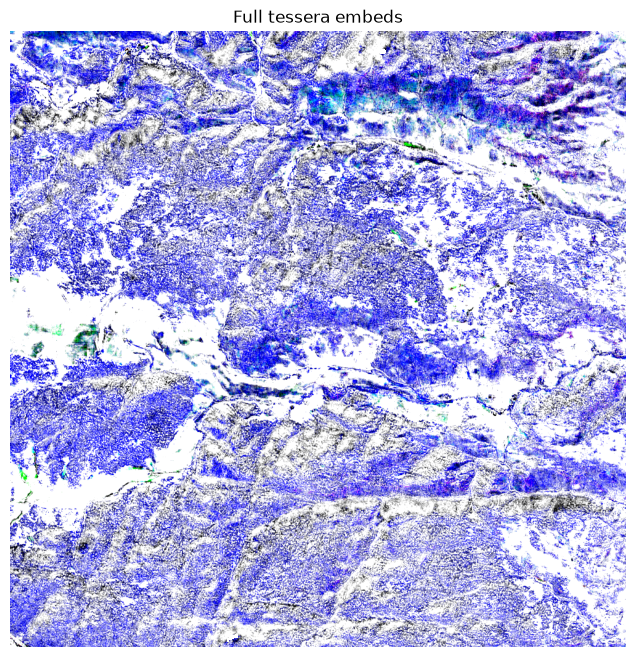

In [6]:
# Upper left corner (I think):
# https://maps.app.goo.gl/tAK8nYtvXbRqJsJZA
# https://epsg.io/transform#s_srs=32613&t_srs=4326&x=457630.0000000&y=4527780.0000000
band = 28
plt.figure(figsize=(10, 8))
plt.imshow(foco_embeddings[:1000, :1000, band:band + 4])
plt.title("Full tessera embeds")
plt.axis("off")
plt.show()

In [7]:
quant_embeddings, quant_scales, quant_transform, quant_crs = gt.read_region_quantized(FOCO_BBOX, year=CO_FIRE_DATASET_YEAR)
quant_embeddings.shape, quant_scales.shape, quant_transform, quant_crs

((4453, 5932, 128),
 (4453, 5932),
 Affine(10.0, 0.0, 457630.0,
        0.0, -10.0, 4527780.0),
 'EPSG:32613')

In [8]:
quant_embeddings[1, 1, :]  # int8

array([  35,  -40,  -88,   34,   15,  -17,  -41,   -8,    6,   52,   12,
          8,  -25,   53,  -19,   92,   -2,   74,   40,   14,  -93,  -38,
        -59,  -87,  -14,  -30,  -40,   62,  -18,   34,   54,   39,  -85,
        -57,   54,  -11,  -56,   27,  -26,   -3,   82,   -2,   35,  -26,
        -18,   25,   19,   60,    8,  -46,   74,   43,  -60,   16,   -9,
        -17,   -9,  -25,  -11,  -42,   34,   16,  -10,  -42,  -23,  -15,
        -25,  -26,   12,  -37,   15,   75,    1,   -6,  -37,   14,   64,
         42, -117,  -25,   27,    8,  -78,  -42,  -11,  -43,  -47,  -14,
       -121,    7,   42,  -34,  -22,  -43,   15,  -62,   41,   79,  -39,
        -28,   35,  -65,  -51,   56,  127,   23,  -15,  -37,  -27,  -56,
        -89,   12,   -7,   71,   -8,  -31,  -69,   26,  -21,   57,  -46,
         69,  -27,  -13,  121,  109,  -19,   11], dtype=int8)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-127..127].


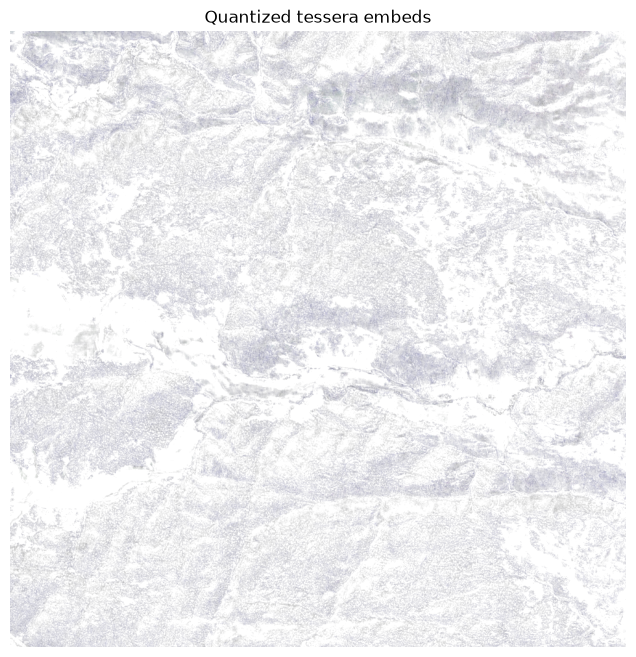

In [9]:
band = 28
plt.figure(figsize=(10, 8))
plt.imshow(quant_embeddings[:1000, :1000, band:band + 4])
plt.title("Quantized tessera embeds")
plt.axis("off")
plt.show()

In [ ]:
def save_tif(multiband_image, transform, crs, file_name="output.tif"):
    """
    `multiband_image` should have the shape: (bands, height, width)

    This creates 256x256 tiles internal to the GeoTIFF for each band dimension.
    """

    print(f"saving multiband_image of shape: {multiband_image.shape}")
    bands, height, width = multiband_image.shape

    with rasterio.open(file_name,
                        mode="w",
                        driver="GTiff",
                        crs=crs,
                        transform=transform,
                        width=width,
                        height=height,
                        count=bands,
                        dtype=multiband_image.dtype,
                        tiled=True,
                        blockxsize=256,
                        blockysize=256) as dst:
        dst.write(multiband_image)

def read_geo_tif(file_name):
    with rasterio.open(file_name, mode="r") as src:
        # Shape: (bands, height, width)
        src_arr = src.read()

        print("Array shape (bands, height, width):", src_arr.shape)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("It tiled?", src.is_tiled)

        # For tiled files, this corresponds to (TileLength, TileWidth)
        print("Block shapes:", len(src.block_shapes))

    return src_arr, src.transform, src.crs

In [11]:
Path("data").mkdir(parents=True, exist_ok=True)
save_tif(np.permute_dims(foco_embeddings, axes=(2, 0, 1)), foco_transform, \
         foco_crs, file_name=f"./data/{CO_FIRE_DATASET_YEAR}_foco_bbox_full.tif")

saving multiband_image of shape: (128, 4453, 5932)


In [12]:
save_tif(np.permute_dims(quant_embeddings, axes=(2, 0, 1)), quant_transform, \
         quant_crs, file_name=f"./data/{CO_FIRE_DATASET_YEAR}_foco_bbox_quant.tif")

saving multiband_image of shape: (128, 4453, 5932)


## Let's look at the target dataset

In [14]:
surface_fuels_embeddings, surface_fuels_transform, surface_fuels_crs = read_geo_tif("./data/SurfaceFuels_COWRA22.tif")
surface_fuels_embeddings = np.permute_dims(surface_fuels_embeddings, axes=(1, 2, 0))

surface_fuels_embeddings.shape, surface_fuels_transform, surface_fuels_crs

Array shape (bands, height, width): (1, 27103, 36876)
CRS: EPSG:26913
Transform: | 20.00, 0.00, 81961.26|
| 0.00,-20.00, 4593232.92|
| 0.00, 0.00, 1.00|
It tiled? True
Block shapes: 1


((27103, 36876, 1),
 Affine(20.0, 0.0, 81961.260721987,
        0.0, -20.0, 4593232.924632752),
 CRS.from_wkt('PROJCS["NAD83 / UTM zone 13N",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-105],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","26913"]]'))

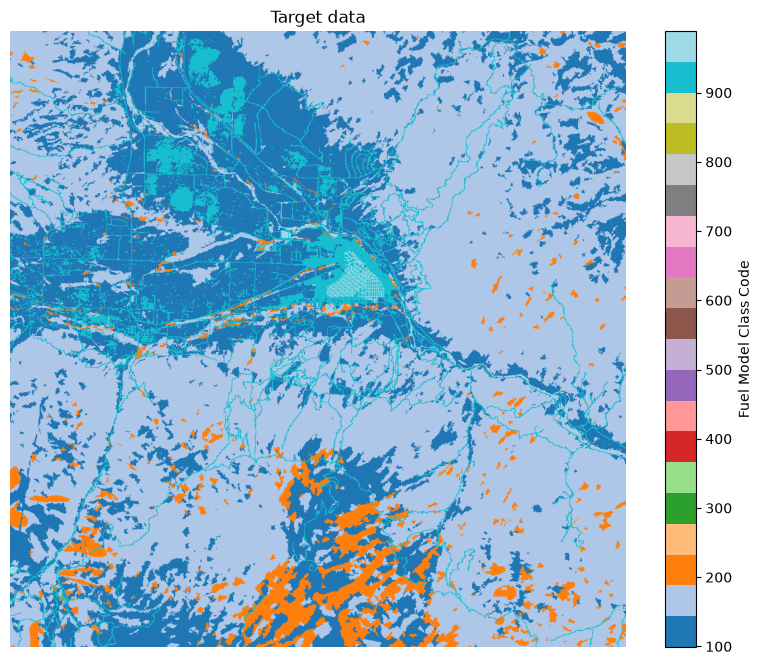

In [15]:
TARGET_DATA_NULL_VALUE = 9999
masked_fuels = np.ma.masked_equal(surface_fuels_embeddings[16000:17000, 16000:17000], TARGET_DATA_NULL_VALUE)

plt.figure(figsize=(10, 8))
plt.imshow(masked_fuels, cmap="tab20")
plt.colorbar(label="Fuel Model Class Code")
plt.title("Target data")
plt.axis("off")
plt.show()

## Next Steps

### COGs and Tiles

Apache Sedona is [designed to work with Cloud Optimized GeoTiffs](https://sedona.apache.org/latest/tutorial/raster/#tile-size-overrides). Applying the above internal tiling scheme when saving the files with `rasterio` does not create a COG.

To do so, use [GDAL Translate](https://gdal.org/en/stable/programs/gdal_translate.html):

1. `deactivate` our venv (so the Anaconda module load can take over).
1. Set the necessary env vars (below location is on department machines, found with `find / -name proj.db 2>/dev/null`).
1. Run GDAL. Full embeddings require a BIGTIFF format (uses larger integers for pointer values).
	
	```bash
	export PROJ_DATA=/usr/share/proj
	export PROJ_LIB=/usr/share/proj
	module load python/anaconda/py3.10-2023.03
	gdal_translate <src_tif> <output_tif> -of COG -co COMPRESS=DEFLATE -co NUM_THREADS=ALL_CPUS -co BIGTIFF=YES
	```
	
	The Anaconda module must be loaded to use a GDAL installation that has the COG format. `gdalinfo <file>` is useful to inspect the result.

1. The full embedding file is still too large to process in Sedona (partitioning crashes with OOM), so split it into smaller files:
	```bash
	gdal_retile.py \
		-v \
		-ps 1024 1024 \
		-co "TILED=YES" \
		-co "COMPRESS=DEFLATE" \
		-co "BLOCKXSIZE=512" \
		-co "BLOCKYSIZE=512" \
		-targetDir ./output_tiles \
		<src_tif>
	```

	† For posterity, I've included this command's output below.

### HDFS 

After all pre-processing is done, move the files into HDFS and delete them from your NFS directory asap so you do not stay over your storage quota.

† `gdal_retile` output, for posterity:
```
2_foco_bbox_full_cog.tif 
Building internal Index for 1 tile(s) ... finished
Warning 1: PROJ: proj_create_from_database: Open of /usr/local/anaconda3/2023.03/share/proj failed
Warning 1: The definition of projected CRS EPSG:32613 got from GeoTIFF keys is not the same as the one from the EPSG registry, which may cause issues during reprojection operations. Set GTIFF_SRS_SOURCE configuration option to EPSG to use official parameters (overriding the ones from GeoTIFF keys), or to GEOKEYS to use custom values from GeoTIFF keys and drop the EPSG code.
Filename: 2022_foco_bbox_full_cog.tif
File Size: 5932x4453x128
Pixel Size: 10.000000 x -10.000000
UL:(457630.000000,4527780.000000)   LR:(516950.000000,4483250.000000)
tileWidth:   1024
tileHeight:  1024
countTilesX: 6
countTilesY: 5
overlap:     0
./output_tiles/2022_foco_bbox_full_cog_1_1.tif : 0|0-->1024-1024
./output_tiles/2022_foco_bbox_full_cog_1_2.tif : 1024|0-->1024-1024
./output_tiles/2022_foco_bbox_full_cog_1_3.tif : 2048|0-->1024-1024
./output_tiles/2022_foco_bbox_full_cog_1_4.tif : 3072|0-->1024-1024
...
./output_tiles/2022_foco_bbox_full_cog_5_4.tif : 3072|4096-->1024-357
./output_tiles/2022_foco_bbox_full_cog_5_5.tif : 4096|4096-->1024-357
./output_tiles/2022_foco_bbox_full_cog_5_6.tif : 5120|4096-->812-357
FINISHED
```